# Unsupervised AD with One Class Support Vector Machines

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import RobustScaler

# Load data




In [ ]:
import pandas as pd
option=2
if option==1:
  # URL to the CSV file (the URL you shared with the students)
  url = "https://drive.google.com/uc?export=download&id=1-6nz0ldZcD6zflGE2QnExvfoMYaioOH4"
elif option==2:
  # URL to the CSV file (the URL you shared with the students)
  #url = "https://drive.google.com/uc?export=download&id=1HTGbKEfArSCAwD9UN7yMb2SYnhhMcu_c"
  url = "https://drive.google.com/uc?export=download&id=1lo7kzz6nGQYiM18dnN5dodgMUDmjym_g"


# Load the CSV into a DataFrame directly from the URL
df = pd.read_csv(url)

# Display the first few rows to confirm
df.head()

,temperature,vibrations,state,label
0,65.908897,5.092387,2.0,0.0
1,36.991467,10.778417,1.0,0.0
2,33.815246,6.019315,1.0,0.0
3,41.070469,6.131392,1.0,0.0
4,70.379023,2.322838,2.0,0.0


# Single state data


In [ ]:
which_state = 1
mask = (df['state']==which_state) | (df['state']==-1)
df_1state = df[mask].copy()


## Visualize the data

Text(0, 0.5, 'Vibrations')

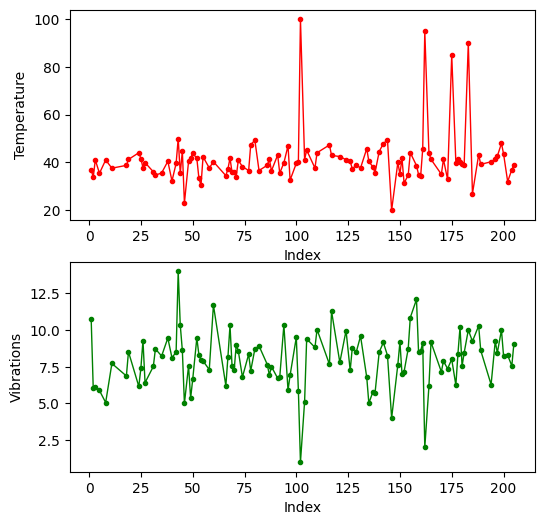

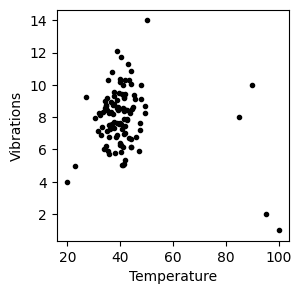

In [ ]:
# serial plots
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].set_xlabel("Index")
axes[0].set_ylabel("Temperature")
axes[0].plot(df_1state['temperature'],'o-r',ms=3,lw=1)

axes[1].set_xlabel("Index")
axes[1].set_ylabel("Vibrations")
axes[1].plot(df_1state['vibrations'],'o-g',ms=3,lw=1)

# scatter plot
plt.figure(figsize=(3,3))
plt.plot(df_1state['temperature'],df_1state['vibrations'],'ok',ms=3)
plt.xlabel('Temperature')
plt.ylabel('Vibrations')

## Extract only the variables from the dataframe

In [ ]:
data = df_1state[['temperature','vibrations']].copy().values

## Rescale data

In [ ]:
from sklearn.metrics import pairwise_distances

# Apply Robust Scaling (using median and IQR)
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)


# Estimate the scale parameter gamma
pairwise_dists = pairwise_distances(data_scaled)
median_dist = np.median(pairwise_dists)
gamma_est = 1 / (2 * median_dist**2)  # Gaussian RBF gamma
print('estimated gamma=',gamma_est)




estimated gamma= 0.29320335049275736


## Plot decision boundaries for several values of $\gamma$

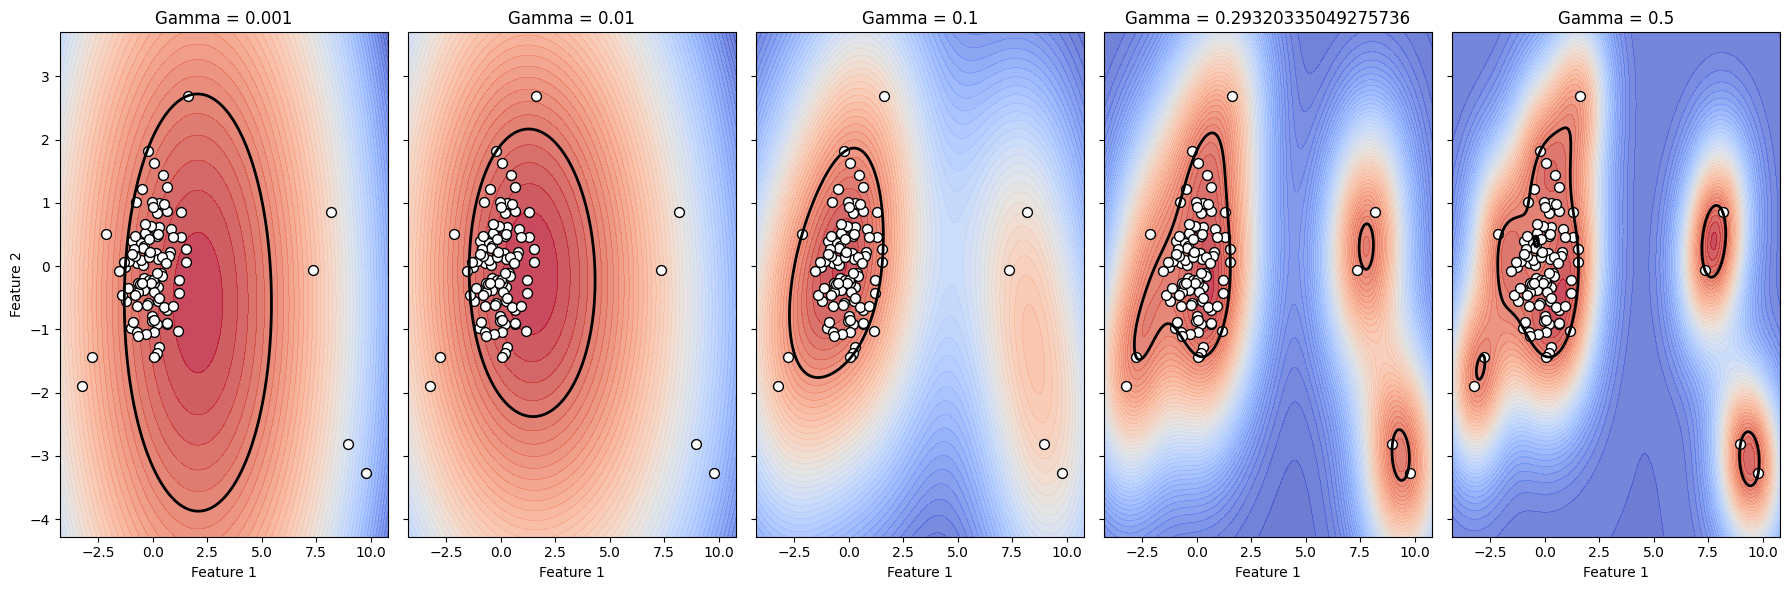

In [ ]:
# Define gamma values to compare
gamma_values = [0.001, 0.01, 0.1,gamma_est,1/data_scaled.shape[1]]
# Create a grid of points to evaluate the model
x_min, x_max = data_scaled[:, 0].min() - 1, data_scaled[:, 0].max() + 1
y_min, y_max = data_scaled[:, 1].min() - 1, data_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Create subplots
fig, axes = plt.subplots(1, len(gamma_values), figsize=(18, 6), sharex=True, sharey=True)

for i, gamma in enumerate(gamma_values):
    # Fit One-Class SVM for the current gamma
    model = OneClassSVM(kernel='rbf', gamma=gamma, nu=0.1)
    model.fit(data_scaled)

    # Compute decision function
    Z = model.decision_function(grid_points)  # Distance to the decision boundary
    Z = Z.reshape(xx.shape)

    # Plot the decision boundary
    ax = axes[i]
    ax.contourf(xx, yy, Z, levels=50, cmap=plt.cm.coolwarm, alpha=0.75)
    ax.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')  # Decision boundary

    # Plot the data points
    ax.scatter(data_scaled[:, 0], data_scaled[:, 1], c='white', edgecolors='k', s=50)

    # Add title and labels
    ax.set_title(f"Gamma = {gamma}")
    ax.set_xlabel("Feature 1")
    if i == 0:  # Only add ylabel to the first subplot
        ax.set_ylabel("Feature 2")


# Adjust layout and show the plot
plt.tight_layout()
plt.show()



## Think
1. What is the effect of $\gamma$?
2. Which value of $\gamma$ would you select?
3. Change the value of $\nu$ and observe the effect on the contour.
4. Select an ideal pair of hyperparameters and run the following code with them.

## Fit and predict OCSVM with a selected value of $\gamma$




In [ ]:
# Apply ocsvm
# OCSVM hyperparameters
nu = 0.1 # An upper bound on the fraction of training errors
gamma = 0.01 # Kernel coefficient

# Fit the One-Class SVM
ocsvm_model = OneClassSVM(gamma=gamma, kernel="rbf", nu=nu)
ocsvm_model.fit(data_scaled)
y_pred = ocsvm_model.predict(data_scaled)

## Plot ocsvm predictions

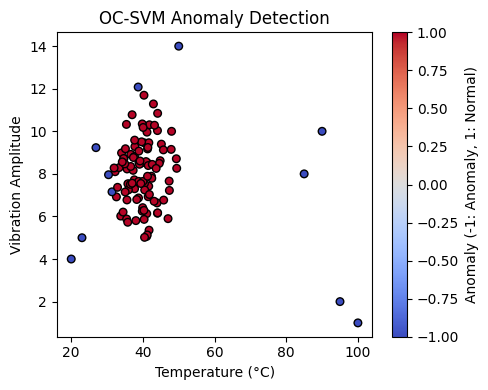

In [ ]:
# Visualize the results
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly detection results
plt.scatter(data[:, 0], data[:, 1], c=y_pred, cmap='coolwarm', edgecolor='k', s=30)
plt.title("OC-SVM Anomaly Detection")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")
plt.colorbar(label='Anomaly (-1: Anomaly, 1: Normal)')

plt.tight_layout()
plt.show()

## Plot ocsvm anomaly scores

In [ ]:
# Get predicted probabilities for the positive class
ocsvm_score = ocsvm_model.score_samples(data_scaled)

# Get decision scores for the test data
decision_scores = ocsvm_model.decision_function(data_scaled)




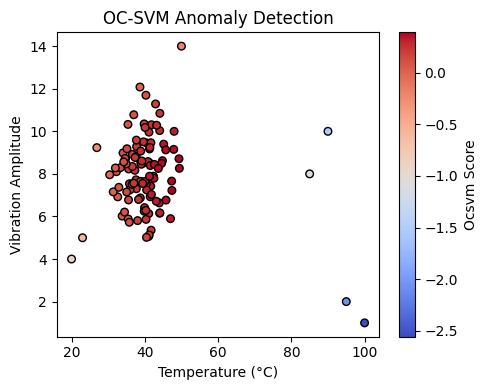

In [ ]:

# Visualize the results using anomaly scores as the color of the points
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly score (more negative means more anomalous)
scatter = plt.scatter(
    data[:, 0], data[:, 1],
    c=decision_scores, cmap='coolwarm', edgecolor='k', s=30
)
plt.title("OC-SVM Anomaly Detection")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")

# Add colorbar to represent anomaly scores
plt.colorbar(scatter, label='Ocsvm Score')

plt.tight_layout()
plt.show()

## Detection threshold

In [ ]:

# calculate  statistics of the score over samples
score_mean =  np.mean(decision_scores)
score_std = np.std(decision_scores)

# define threshold for detection
score_threshold = score_mean - 3*score_std

# count how many anomalies are detected
np.sum(decision_scores < score_threshold)

np.int64(3)

Text(0.5, 0, 'anomaly score')

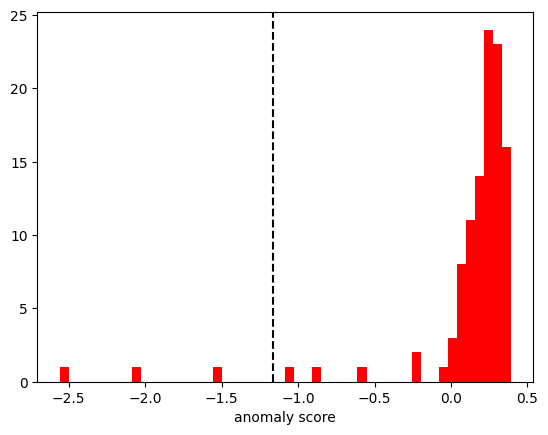

In [ ]:
plt.figure()
plt.hist(decision_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Detection threshold: robust

In [ ]:
# calculate  statistics of the score over samples
score_median =  np.median(decision_scores)
score_iqr = np.quantile(decision_scores,0.75)-np.quantile(decision_scores,0.25)

# define threshold for detection
score_threshold = score_median - 3*score_iqr

# count how many anomalies are detected
np.sum(decision_scores < score_threshold)

np.int64(6)

## Plot robust threshold

Text(0.5, 0, 'anomaly score')

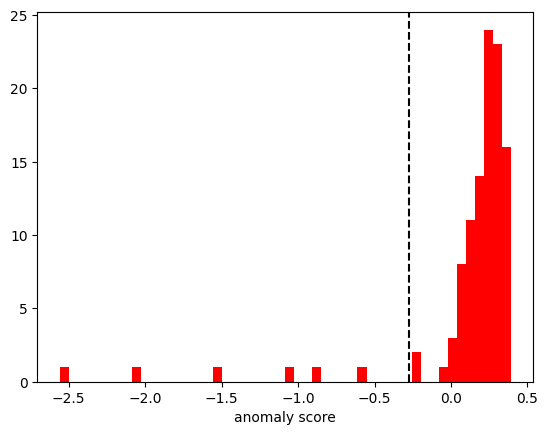

In [ ]:
plt.figure()
plt.hist(decision_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Think
1. Could you think of a better way to set the threshold? Hint: look at the shape of the score histogram.

# Two state data


## Random shuffling of the rows of the dataframe

In [ ]:
# Shuffle the rows of the DataFrame
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


## Visualize the data

Text(0, 0.5, 'Vibrations')

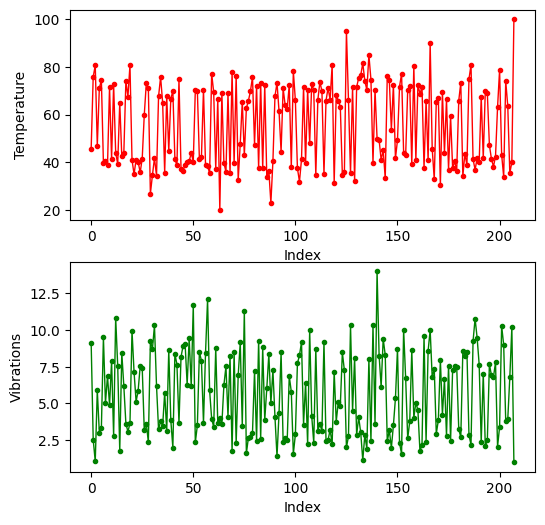

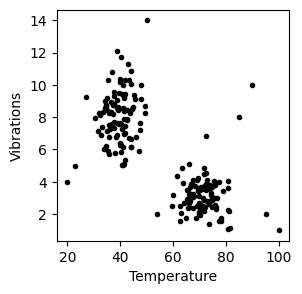

In [ ]:
# serial plots
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].set_xlabel("Index")
axes[0].set_ylabel("Temperature")
axes[0].plot(df['temperature'],'o-r',ms=3,lw=1)

axes[1].set_xlabel("Index")
axes[1].set_ylabel("Vibrations")
axes[1].plot(df['vibrations'],'o-g',ms=3,lw=1)

# scatter plot
plt.figure(figsize=(3,3))
plt.plot(df['temperature'],df['vibrations'],'ok',ms=3)
plt.xlabel('Temperature')
plt.ylabel('Vibrations')

## Extract only the variables from the dataframe

In [ ]:
data = df[['temperature','vibrations']].copy().values

## Fit and predict with ocsvm

In [ ]:
# Apply Robust Scaling (using median and IQR)
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# Estimate the scale parameter gamma
pairwise_dists = pairwise_distances(data_scaled)
median_dist = np.median(pairwise_dists)
gamma_est = 1 / (2 * median_dist**2)  # Gaussian RBF gamma
print('estimated gamma=',gamma_est)




estimated gamma= 0.5269876975040031


## Plot decision boundaries for several values of $\gamma$

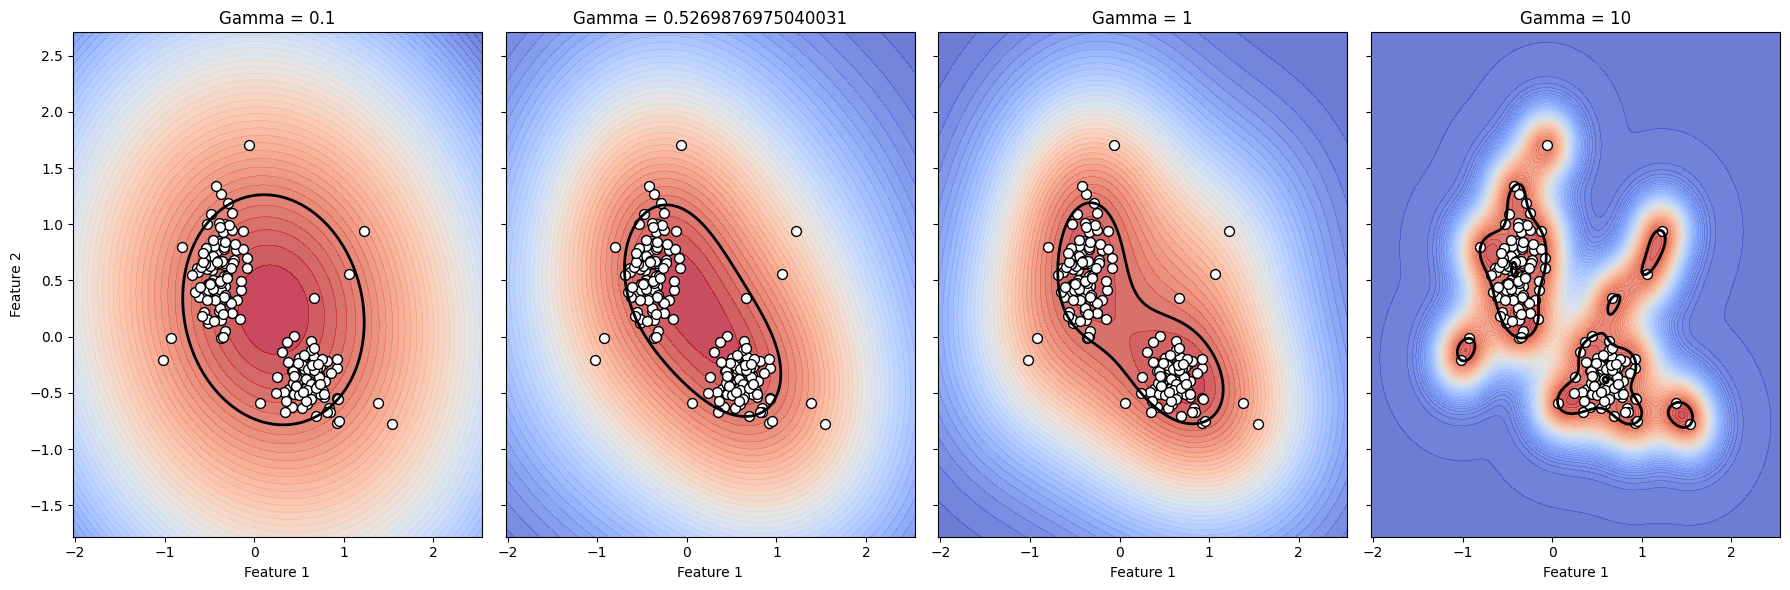

In [ ]:
# Define gamma values to compare
gamma_values = [0.1,gamma_est,1,10]
# Create a grid of points to evaluate the model
x_min, x_max = data_scaled[:, 0].min() - 1, data_scaled[:, 0].max() + 1
y_min, y_max = data_scaled[:, 1].min() - 1, data_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Create subplots
fig, axes = plt.subplots(1, len(gamma_values), figsize=(18, 6), sharex=True, sharey=True)

for i, gamma in enumerate(gamma_values):
    # Fit One-Class SVM for the current gamma
    model = OneClassSVM(kernel='rbf', gamma=gamma, nu=0.08)
    model.fit(data_scaled)

        # Compute decision function
    Z = model.decision_function(grid_points)  # Distance to the decision boundary
    Z = Z.reshape(xx.shape)

    # Plot the decision boundary
    ax = axes[i]
    ax.contourf(xx, yy, Z, levels=50, cmap=plt.cm.coolwarm, alpha=0.75)
    ax.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')  # Decision boundary

    # Plot the data points
    ax.scatter(data_scaled[:, 0], data_scaled[:, 1], c='white', edgecolors='k', s=50, label='Inliers')

    # Add title and labels
    ax.set_title(f"Gamma = {gamma}")
    ax.set_xlabel("Feature 1")
    if i == 0:  # Only add ylabel to the first subplot
        ax.set_ylabel("Feature 2")

# Add a legend to the last subplot
#axes[-1].legend(loc="upper right", frameon=True)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

#fig.savefig('OCSVM_boundary.pdf')  # Save the figure

# Download the figure
#from google.colab import files
#files.download('OCSVM_boundary.pdf')

## Fit and predict OCSVM with selected hyperparameters

In [ ]:
nu = 0.08
gamma = 1

# Fit the One-Class SVM
ocsvm_model = OneClassSVM(gamma=gamma, kernel="rbf", nu=nu)
ocsvm_model.fit(data_scaled)
y_pred = ocsvm_model.predict(data_scaled)



## Plot ocsvm predictions

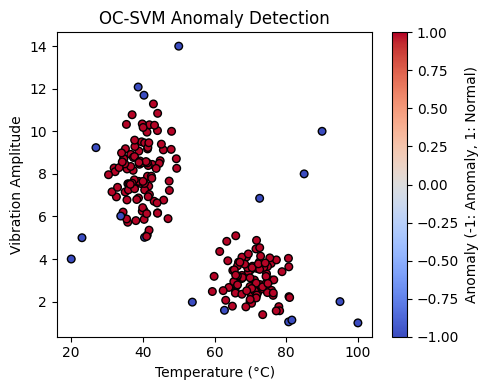

In [ ]:
# Visualize the results
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly detection results
plt.scatter(data[:, 0], data[:, 1], c=y_pred, cmap='coolwarm', edgecolor='k', s=30)
plt.title("OC-SVM Anomaly Detection")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")
plt.colorbar(label='Anomaly (-1: Anomaly, 1: Normal)')

plt.tight_layout()
plt.show()

## Plot ocsvm anomaly scores

In [ ]:
# Get predicted probabilities for the positive class
ocsvm_score = ocsvm_model.score_samples(data_scaled)

# Get decision scores for the test data
decision_scores = ocsvm_model.decision_function(data_scaled)


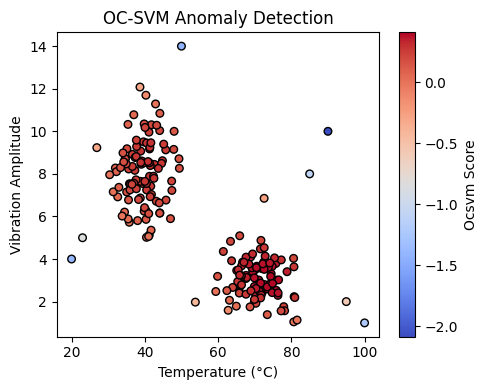

In [ ]:

# Visualize the results using anomaly scores as the color of the points
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly score (more negative means more anomalous)
scatter = plt.scatter(
    data[:, 0], data[:, 1],
    c=decision_scores, cmap='coolwarm', edgecolor='k', s=30
)
plt.title("OC-SVM Anomaly Detection")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")

# Add colorbar to represent anomaly scores
plt.colorbar(scatter, label='Ocsvm Score')

plt.tight_layout()
plt.show()

## Detection threshold

In [ ]:

# calculate  statistics of the score over samples
score_mean =  np.mean(decision_scores)
score_std = np.std(decision_scores)

# define threshold for detection
score_threshold = score_mean - 3*score_std

# count how many anomalies are detected
np.sum(decision_scores < score_threshold)

np.int64(6)

Text(0.5, 0, 'anomaly score')

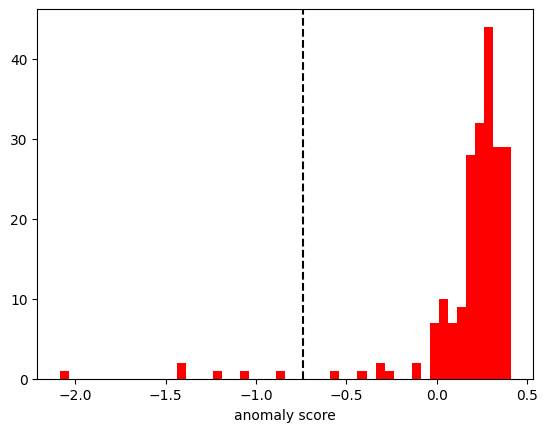

In [ ]:
plt.figure()
plt.hist(decision_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Detection threshold: robust

In [ ]:
# calculate  statistics of the score over samples
score_median =  np.median(decision_scores)
score_iqr = np.quantile(decision_scores,0.75)-np.quantile(decision_scores,0.25)

# define threshold for detection
score_threshold = score_median - 3*score_iqr

# count how many anomalies are detected
np.sum(decision_scores < score_threshold)

np.int64(11)

## Plot robust threshold

Text(0.5, 0, 'anomaly score')

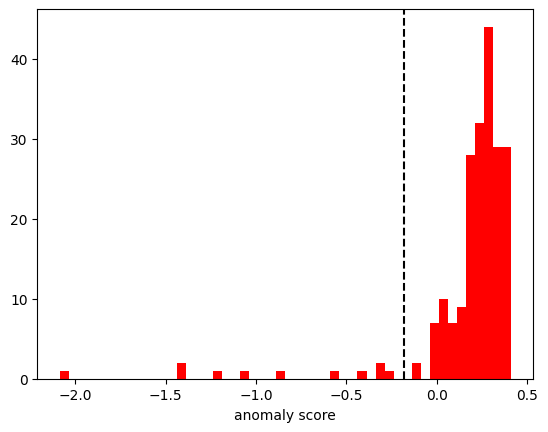

In [ ]:
plt.figure()
plt.hist(decision_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

# Evaluation

In [ ]:
anomaly_scores = -decision_scores # standard: anomalies have a higher score
true_labels = df['label']

## Confusion matrix

In [ ]:
# select a decision threshold and use it to predict
threshold = -score_threshold
predicted_labels = (anomaly_scores >= threshold).astype(int)
# True Positives, False Positives, False Negatives
tp = ((predicted_labels == 1) & (true_labels == 1)).sum()
tn = ((predicted_labels == 0) & (true_labels == 0)).sum()
fp = ((predicted_labels == 1) & (true_labels == 0)).sum()
fn = ((predicted_labels == 0) & (true_labels == 1)).sum()

print(tp,tn,fp,fn)

7 196 4 1


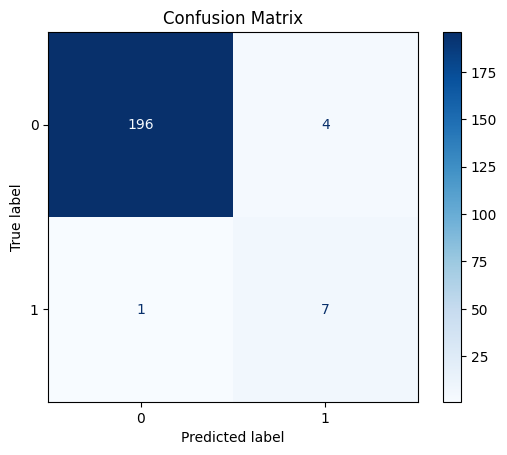

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(true_labels, predicted_labels)
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

## Precision-recall curve

In [ ]:
def calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_array):
    """
    Calculate precision and recall for a given set of thresholds from scratch.

    Parameters:
    - anomaly_scores: Array-like, the anomaly scores output by the isolation forest.
                      Higher scores indicate a higher likelihood of being an anomaly.
    - true_labels: Array-like, ground truth labels (0 for normal, 1 for anomalies).
    - threshold_array: List or array of thresholds to evaluate.

    Returns:
    - precision: List of precision values for each threshold.
    - recall: List of recall values for each threshold.
    """
    precision = []
    recall = []

    for threshold in threshold_array:
        # Classify points as anomalies (1) or normal (0) based on the threshold
        predicted_labels = (anomaly_scores >= threshold).astype(int)

        # True Positives, False Positives, False Negatives
        tp = ((predicted_labels == 1) & (true_labels == 1)).sum()
        fp = ((predicted_labels == 1) & (true_labels == 0)).sum()
        fn = ((predicted_labels == 0) & (true_labels == 1)).sum()

        # Precision and Recall calculations
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0

        precision.append(prec)
        recall.append(rec)

    return precision, recall



### Define a set of thresholds

In [ ]:
threshold_arr = np.arange(np.min(anomaly_scores),np.max(anomaly_scores),0.01)


### calculate precision and recall using own function

In [ ]:
precision, recall = calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_arr)

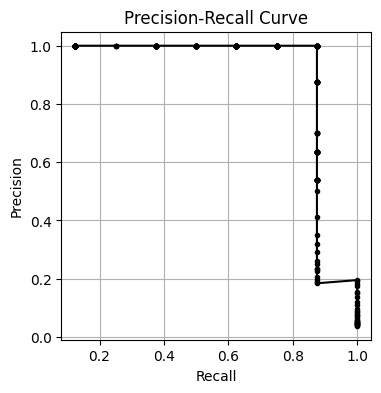

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall,precision,'ko-',ms=3)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()
plt.show()

### calculate precision and recall using sklearn function

In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

def calculate_pr_curve(anomaly_scores, true_labels, plot=True):
    """
    Calculate and optionally plot the Precision-Recall (PR) curve.

    Parameters:
    - anomaly_scores: Array-like, the anomaly scores output by the isolation forest.
                      Higher scores should correspond to higher likelihood of being an anomaly.
    - true_labels: Array-like, ground truth labels (0 for normal, 1 for anomalies).
    - plot: Boolean, whether to plot the PR curve (default is True).

    Returns:
    - precision: Array of precision values.
    - recall: Array of recall values.
    - thresholds: Array of thresholds used to compute precision and recall.
    """
    # Calculate Precision-Recall curve
    precision, recall, thresholds = precision_recall_curve(true_labels, anomaly_scores)

    if plot:
        # Plot the PR curve
        plt.figure(figsize=(4, 4))
        plt.plot(recall, precision, marker='.', label='PR Curve')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curve')
        plt.legend()
        plt.grid()
        plt.show()

    return precision, recall, thresholds


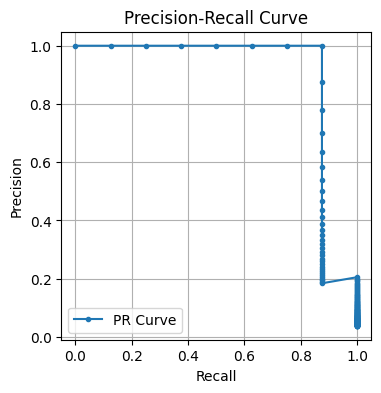

In [ ]:
prec, rec, thresholds = calculate_pr_curve(anomaly_scores,df['label'])

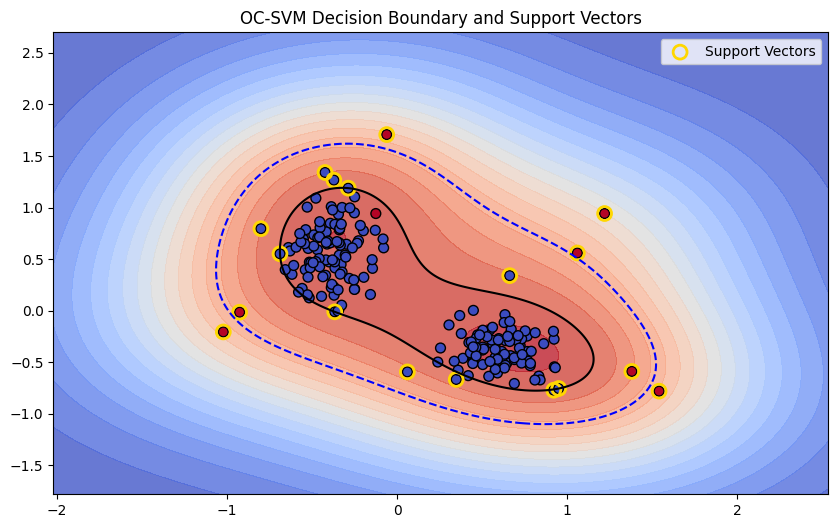

In [ ]:
# Create a mesh grid for plotting the decision boundary
x_min, x_max = data_scaled[:, 0].min() - 1, data_scaled[:, 0].max() + 1
y_min, y_max = data_scaled[:, 1].min() - 1, data_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict on the mesh grid
Z = ocsvm_model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary and margins
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, levels=20, cmap="coolwarm", alpha=0.8)
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=['blue', 'black', 'red'], linestyles=['--', '-', '--'])

# Scatter plot of data points
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=true_labels, cmap='coolwarm', s=50, edgecolors='k')

# Highlight the support vectors
plt.scatter(ocsvm_model.support_vectors_[:, 0], ocsvm_model.support_vectors_[:, 1],
            s=100, facecolors='none', edgecolors='gold', linewidths=2, label='Support Vectors')

# Labels and title
plt.title("OC-SVM Decision Boundary and Support Vectors")
#plt.xlabel(data_scaled.columns[0])
#plt.ylabel(data_scaled.columns[1])
plt.legend()
plt.show()